In [ ]:
import warnings
warnings.filterwarnings("ignore")





```
Mengimpor library yang digunakan untuk proses clustering, visualisasi, dan evaluasi.
```





In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import dendrogram, linkage
from wordcloud import WordCloud



```
Menggabungkan data meals dan ingredients menjadi satu kumpulan dokumen.
```



In [ ]:
df = pd.read_csv("hasil_preprocessing_exercise_4.csv")

meals = df["meals_cleaned"].dropna().astype(str).tolist()
ingredients = df["ingredients_cleaned"].dropna().astype(str).tolist()

documents = meals + ingredients

df_preprocessed = pd.DataFrame({
    "prepro": documents
})

print("Jumlah dokumen:", len(df_preprocessed))
display(df_preprocessed)

Jumlah dokumen: 12


,prepro
0,biss jaggery modak
1,honey cookies
2,gingerbread waffles
3,sauerkraut fish salad
4,carrot bean fritters
5,apple pie
6,quark rhubarb pie
7,papaya salad
8,chicken
9,salmon


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive




```
Mengubah kumpulan teks menjadi representasi numerik menggunakan TF-IDF.

In [ ]:
vectorizer = TfidfVectorizer()

X = vectorizer.fit_transform(df_preprocessed["prepro"])

df_FE = pd.DataFrame(
    X.toarray(),
    columns=vectorizer.get_feature_names_out()
)

print("Ukuran matriks TF-IDF:", df_FE.shape)
display(df_FE)

Ukuran matriks TF-IDF: (12, 22)


,apple,bean,beef,biss,carrot,chicken,cookies,fish,fritters,gingerbread,...,modak,papaya,pie,pork,quark,rhubarb,salad,salmon,sauerkraut,waffles
0,0.000000,0.00000,0.0,0.57735,0.00000,0.0,0.000000,0.000000,0.00000,0.000000,...,0.57735,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000
1,0.000000,0.00000,0.0,0.00000,0.00000,0.0,0.707107,0.000000,0.00000,0.000000,...,0.00000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000
2,0.000000,0.00000,0.0,0.00000,0.00000,0.0,0.000000,0.000000,0.00000,0.707107,...,0.00000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.707107
3,0.000000,0.00000,0.0,0.00000,0.00000,0.0,0.000000,0.604392,0.00000,0.000000,...,0.00000,0.000000,0.000000,0.0,0.000000,0.000000,0.519058,0.0,0.604392,0.000000
4,0.000000,0.57735,0.0,0.00000,0.57735,0.0,0.000000,0.000000,0.57735,0.000000,...,0.00000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000
5,0.758631,0.00000,0.0,0.00000,0.00000,0.0,0.000000,0.000000,0.00000,0.000000,...,0.00000,0.000000,0.651521,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000
6,0.000000,0.00000,0.0,0.00000,0.00000,0.0,0.000000,0.000000,0.00000,0.000000,...,0.00000,0.000000,0.519058,0.0,0.604392,0.604392,0.000000,0.0,0.000000,0.000000
7,0.000000,0.00000,0.0,0.00000,0.00000,0.0,0.000000,0.000000,0.00000,0.000000,...,0.00000,0.758631,0.000000,0.0,0.000000,0.000000,0.651521,0.0,0.000000,0.000000
8,0.000000,0.00000,0.0,0.00000,0.00000,1.0,0.000000,0.000000,0.00000,0.000000,...,0.00000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000
9,0.000000,0.00000,0.0,0.00000,0.00000,0.0,0.000000,0.000000,0.00000,0.000000,...,0.00000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,1.0,0.000000,0.000000


In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from wordcloud import WordCloud



```
Menghitung nilai inertia untuk beberapa jumlah cluster.
```



In [ ]:
k = range(1, 7)
inertia = []

for i in k:
    km_model = KMeans(n_clusters=i, random_state=10)
    km_model.fit(df_FE)
    inertia.append(km_model.inertia_)

print("Jumlah cluster:", list(k))
print("Nilai inertia:", inertia)

Jumlah cluster: [1, 2, 3, 4, 5, 6]
Nilai inertia: [10.887274188688549, 9.594187079278777, 8.577278207582061, 7.5652004420844055, 6.323645132131297, 5.323645132131297]




```
Menampilkan grafik untuk melihat penurunan nilai inertia.
```



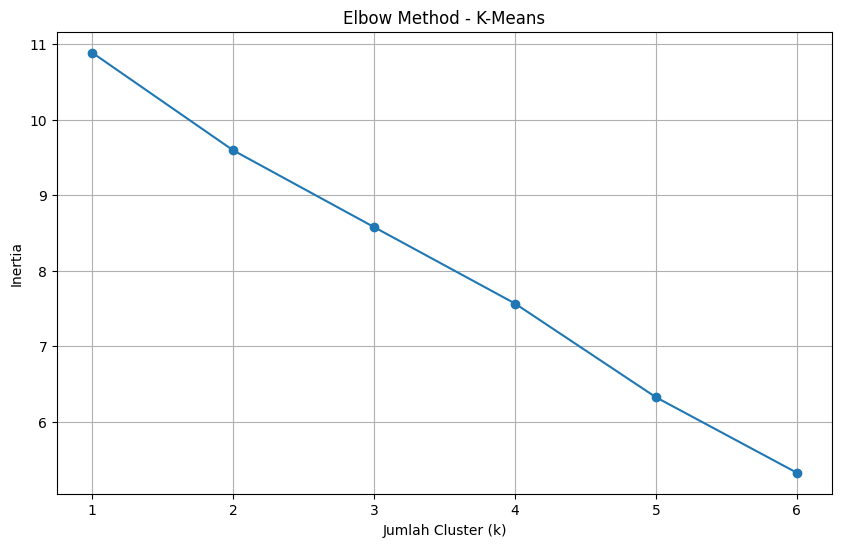

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(k, inertia, marker="o")

plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method - K-Means")
plt.grid()
plt.show()



```
Menghitung Silhouette Score untuk mengetahui kualitas hasil clustering pada setiap nilai k.
```



In [ ]:
silhouette_scores = []

for i in range(2, 7):
    km_model = KMeans(n_clusters=i, random_state=10)
    labels = km_model.fit_predict(df_FE)

    score = silhouette_score(df_FE, labels)
    silhouette_scores.append(score)

hasil_silhouette = pd.DataFrame({
    "Jumlah Cluster": range(2, 7),
    "Silhouette Score": silhouette_scores
})

display(hasil_silhouette)

,Jumlah Cluster,Silhouette Score
0,2,0.034532
1,3,0.035519
2,4,0.036259
3,5,0.062158
4,6,0.062158




```
Memvisualisasikan perbandingan nilai Silhouette Score.
```



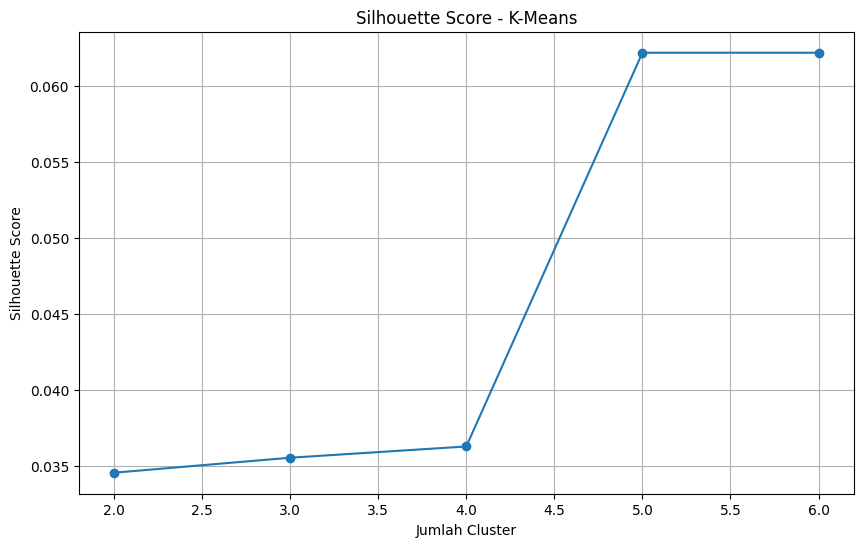

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(range(2, 7), silhouette_scores, marker="o")

plt.xlabel("Jumlah Cluster")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score - K-Means")
plt.grid()
plt.show()



```
Menggunakan 5 cluster berdasarkan hasil evaluasi sebelumnya. Nilai ini merupakan pilihan sementara karena skor tertinggi pada grafik sebelumnya berdekatan dengan k=6.
```



In [ ]:
n_clusters = 5

kM = KMeans(
    n_clusters=n_clusters,
    random_state=10
)

kM.fit(df_FE)

df_preprocessed["Kmeans_label"] = kM.labels_

display(df_preprocessed)

,prepro,Kmeans_label
0,biss jaggery modak,2
1,honey cookies,2
2,gingerbread waffles,2
3,sauerkraut fish salad,4
4,carrot bean fritters,2
5,apple pie,1
6,quark rhubarb pie,1
7,papaya salad,4
8,chicken,3
9,salmon,0




```
Menghitung kualitas clustering dari model K-Means yang telah dipilih.
```



In [ ]:
score_kmeans = silhouette_score(
    df_FE,
    kM.labels_,
    metric="euclidean"
)

print("Silhouette Score K-Means:", score_kmeans)

Silhouette Score K-Means: 0.06215840699617922




```
Mengetahui jumlah dokumen yang masuk ke masing-masing cluster.
```



In [ ]:
# Ensure Kmeans_label is assigned in case the dataframe was re-initialized
if "Kmeans_label" not in df_preprocessed.columns:
    df_preprocessed["Kmeans_label"] = kM.labels_

jumlah_cluster = (
    df_preprocessed["Kmeans_label"]
    .value_counts()
    .sort_index()
)

print("Jumlah anggota setiap cluster:")
display(jumlah_cluster)

Jumlah anggota setiap cluster:


,count
Kmeans_label,
0,1
1,2
2,5
3,2
4,2



```
WordCloud K-Means
```





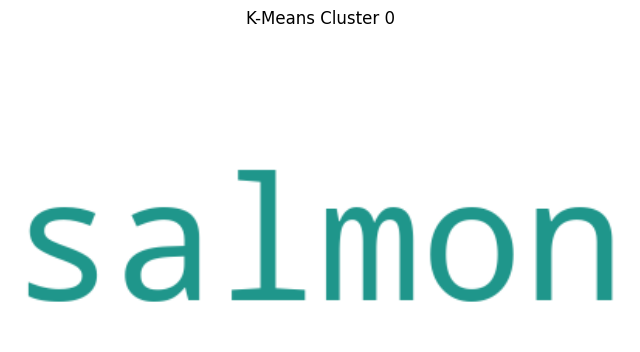

In [ ]:
df_c0 = df_preprocessed[df_preprocessed["Kmeans_label"] == 0]
text_c0 = " ".join(df_c0["prepro"].values)

wordcloud_c0 = WordCloud(
    background_color="white",
    max_words=100
).generate(text_c0)

plt.figure(figsize=(8, 5))
plt.imshow(wordcloud_c0, interpolation="bilinear")
plt.title("K-Means Cluster 0")
plt.axis("off")
plt.show()

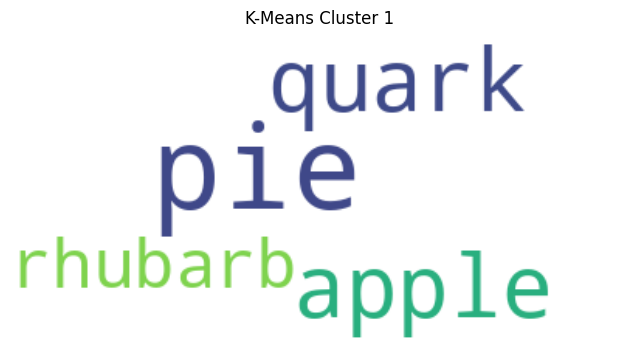

In [ ]:
df_c1 = df_preprocessed[df_preprocessed["Kmeans_label"] == 1]
text_c1 = " ".join(df_c1["prepro"].values)

wordcloud_c1 = WordCloud(
    background_color="white",
    max_words=100
).generate(text_c1)

plt.figure(figsize=(8, 5))
plt.imshow(wordcloud_c1, interpolation="bilinear")
plt.title("K-Means Cluster 1")
plt.axis("off")
plt.show()

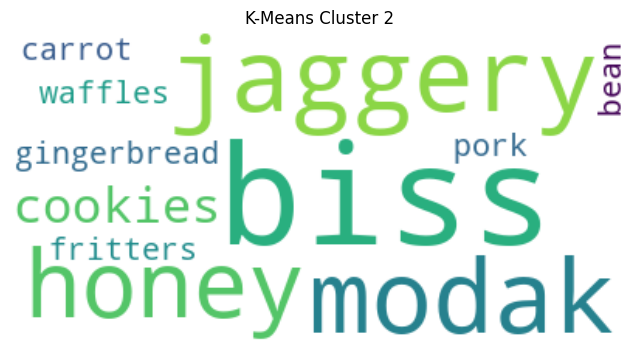

In [ ]:
df_c2 = df_preprocessed[df_preprocessed["Kmeans_label"] == 2]
text_c2 = " ".join(df_c2["prepro"].values)

wordcloud_c2 = WordCloud(
    background_color="white",
    max_words=100
).generate(text_c2)

plt.figure(figsize=(8, 5))
plt.imshow(wordcloud_c2, interpolation="bilinear")
plt.title("K-Means Cluster 2")
plt.axis("off")
plt.show()

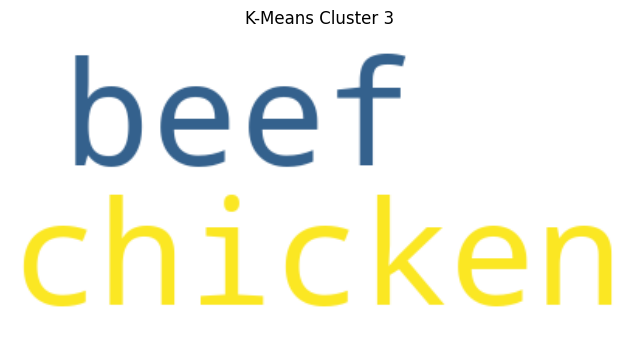

In [ ]:
df_c3 = df_preprocessed[df_preprocessed["Kmeans_label"] == 3]
text_c3 = " ".join(df_c3["prepro"].values)

wordcloud_c3 = WordCloud(
    background_color="white",
    max_words=100
).generate(text_c3)

plt.figure(figsize=(8, 5))
plt.imshow(wordcloud_c3, interpolation="bilinear")
plt.title("K-Means Cluster 3")
plt.axis("off")
plt.show()

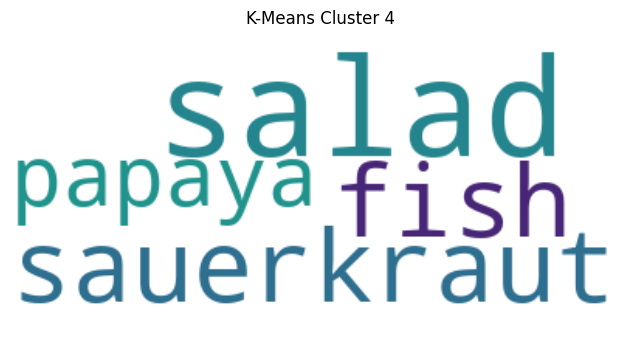

In [ ]:
df_c4 = df_preprocessed[df_preprocessed["Kmeans_label"] == 4]
text_c4 = " ".join(df_c4["prepro"].values)

wordcloud_c4 = WordCloud(
    background_color="white",
    max_words=100
).generate(text_c4)

plt.figure(figsize=(8, 5))
plt.imshow(wordcloud_c4, interpolation="bilinear")
plt.title("K-Means Cluster 4")
plt.axis("off")
plt.show()



```
Menggambarkan proses penggabungan cluster berdasarkan jarak terdekat antardata.
```



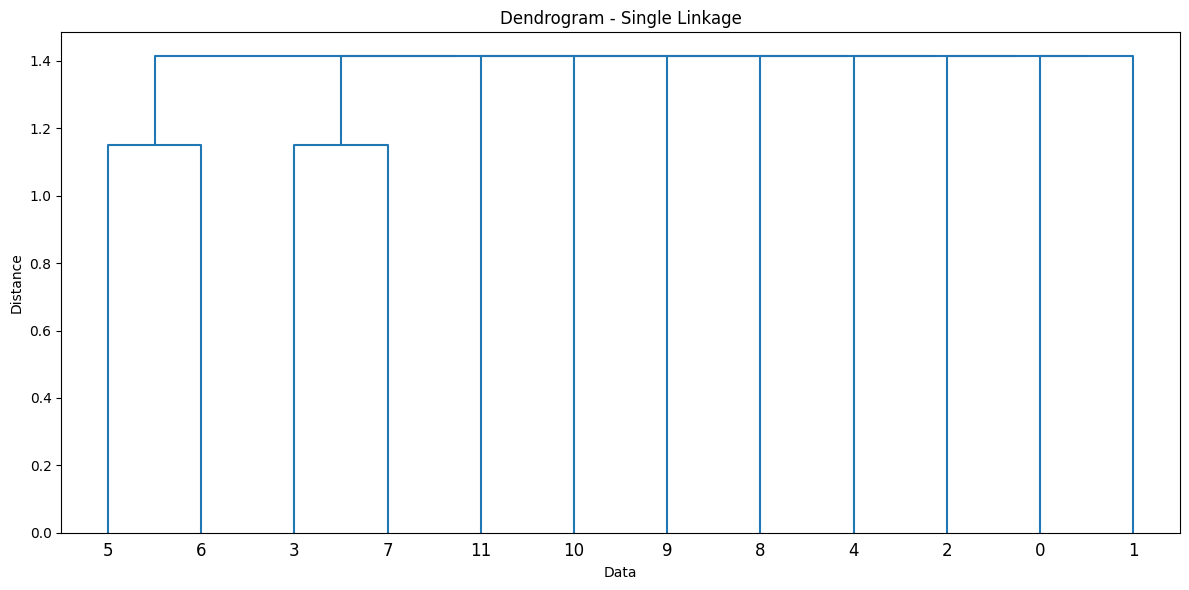

In [ ]:
linkage_single = linkage(
    df_FE,
    method="single",
    metric="euclidean"
)

plt.figure(figsize=(12, 6))
dendrogram(linkage_single)

plt.title("Dendrogram - Single Linkage")
plt.xlabel("Data")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()



```
Mengelompokkan data menggunakan metode Single Linkage dengan 5 cluster agar dapat dibandingkan dengan K-Means.
```



In [ ]:
hierarchical_single = AgglomerativeClustering(
    n_clusters=n_clusters,
    linkage="single",
    metric="euclidean"
)

labels_single = hierarchical_single.fit_predict(df_FE)

df_preprocessed["Single_label"] = labels_single

display(df_preprocessed)

,prepro,Kmeans_label,Single_label
0,biss jaggery modak,2,0
1,honey cookies,2,0
2,gingerbread waffles,2,0
3,sauerkraut fish salad,4,2
4,carrot bean fritters,2,0
5,apple pie,1,1
6,quark rhubarb pie,1,1
7,papaya salad,4,2
8,chicken,3,0
9,salmon,0,0




```
Mengukur kualitas hasil pengelompokan menggunakan metode Single Linkage.
```



In [ ]:
score_single = silhouette_score(
    df_FE,
    labels_single,
    metric="euclidean"
)

print("Silhouette Score Single Linkage:", score_single)

Silhouette Score Single Linkage: 0.06215840699617925




```
Menampilkan jumlah dokumen pada masing-masing cluster Single Linkage.
```



In [ ]:
jumlah_single = (
    df_preprocessed["Single_label"]
    .value_counts()
    .sort_index()
)

print("Jumlah anggota setiap cluster Single Linkage:")
display(jumlah_single)

Jumlah anggota setiap cluster Single Linkage:


,count
Single_label,
0,6
1,2
2,2
3,1
4,1




```
WordCloud Single Linkage
```



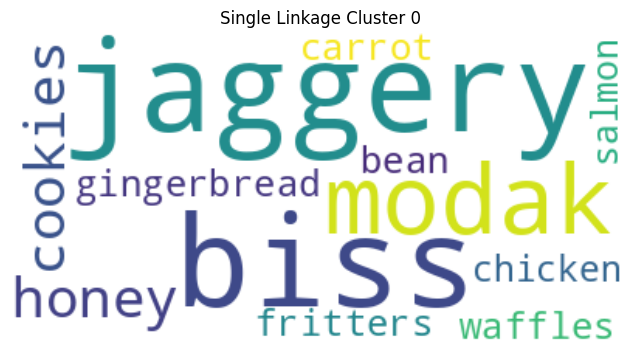

In [ ]:
df_s0 = df_preprocessed[df_preprocessed["Single_label"] == 0]
text_s0 = " ".join(df_s0["prepro"].values)

wordcloud_s0 = WordCloud(
    background_color="white",
    max_words=100
).generate(text_s0)

plt.figure(figsize=(8, 5))
plt.imshow(wordcloud_s0, interpolation="bilinear")
plt.title("Single Linkage Cluster 0")
plt.axis("off")
plt.show()

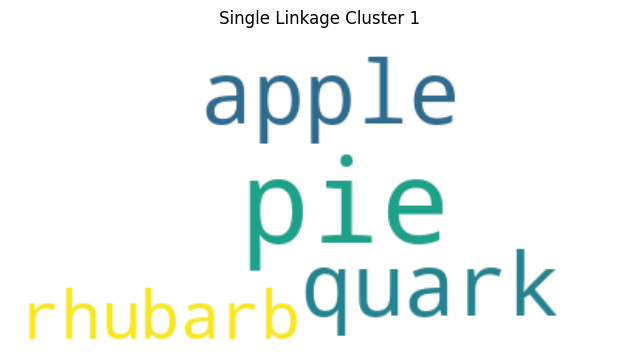

In [ ]:
df_s1 = df_preprocessed[df_preprocessed["Single_label"] == 1]
text_s1 = " ".join(df_s1["prepro"].values)

wordcloud_s1 = WordCloud(
    background_color="white",
    max_words=100
).generate(text_s1)

plt.figure(figsize=(8, 5))
plt.imshow(wordcloud_s1, interpolation="bilinear")
plt.title("Single Linkage Cluster 1")
plt.axis("off")
plt.show()

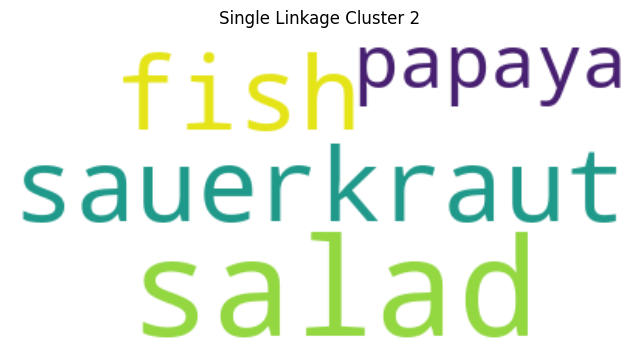

In [ ]:
df_s2 = df_preprocessed[df_preprocessed["Single_label"] == 2]
text_s2 = " ".join(df_s2["prepro"].values)

wordcloud_s2 = WordCloud(
    background_color="white",
    max_words=100
).generate(text_s2)

plt.figure(figsize=(8, 5))
plt.imshow(wordcloud_s2, interpolation="bilinear")
plt.title("Single Linkage Cluster 2")
plt.axis("off")
plt.show()

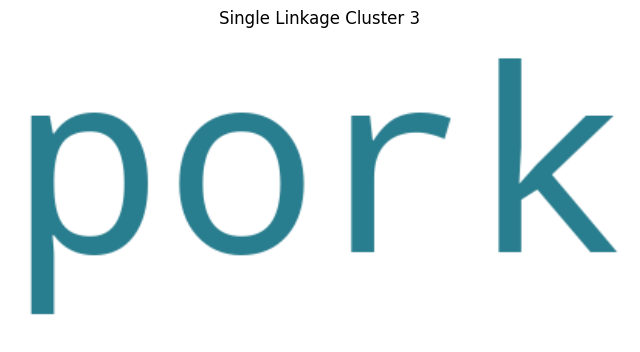

In [ ]:
df_s3 = df_preprocessed[df_preprocessed["Single_label"] == 3]
text_s3 = " ".join(df_s3["prepro"].values)

wordcloud_s3 = WordCloud(
    background_color="white",
    max_words=100
).generate(text_s3)

plt.figure(figsize=(8, 5))
plt.imshow(wordcloud_s3, interpolation="bilinear")
plt.title("Single Linkage Cluster 3")
plt.axis("off")
plt.show()

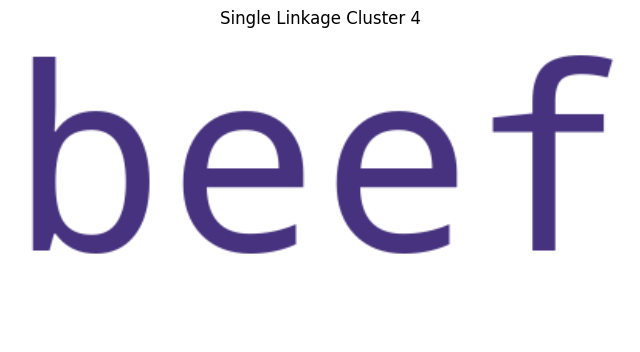

In [ ]:
df_s4 = df_preprocessed[df_preprocessed["Single_label"] == 4]
text_s4 = " ".join(df_s4["prepro"].values)

wordcloud_s4 = WordCloud(
    background_color="white",
    max_words=100
).generate(text_s4)

plt.figure(figsize=(8, 5))
plt.imshow(wordcloud_s4, interpolation="bilinear")
plt.title("Single Linkage Cluster 4")
plt.axis("off")
plt.show()


```
Membandingkan kualitas hasil K-Means dan Single Linkage berdasarkan Silhouette Score.
```


In [ ]:
hasil_perbandingan = pd.DataFrame({
    "Metode Clustering": [
        "K-Means",
        "Single Linkage"
    ],
    "Silhouette Score": [
        score_kmeans,
        score_single
    ]
})

display(hasil_perbandingan)

,Metode Clustering,Silhouette Score
0,K-Means,0.062158
1,Single Linkage,0.062158




```
Menampilkan perbandingan nilai Silhouette Score kedua metode.
```



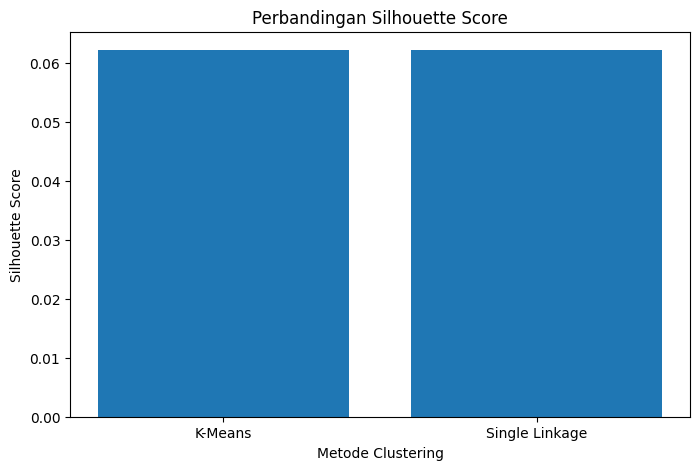

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    hasil_perbandingan["Metode Clustering"],
    hasil_perbandingan["Silhouette Score"]
)

plt.xlabel("Metode Clustering")
plt.ylabel("Silhouette Score")
plt.title("Perbandingan Silhouette Score")
plt.show()



```
Menampilkan dokumen beserta label cluster dari kedua metode.
```



In [ ]:
hasil_akhir = df_preprocessed[
    ["prepro", "Kmeans_label", "Single_label"]
]

display(hasil_akhir)

,prepro,Kmeans_label,Single_label
0,biss jaggery modak,2,0
1,honey cookies,2,0
2,gingerbread waffles,2,0
3,sauerkraut fish salad,4,2
4,carrot bean fritters,2,0
5,apple pie,1,1
6,quark rhubarb pie,1,1
7,papaya salad,4,2
8,chicken,3,0
9,salmon,0,0




```
Membuat dendrogram Complete Linkage
```



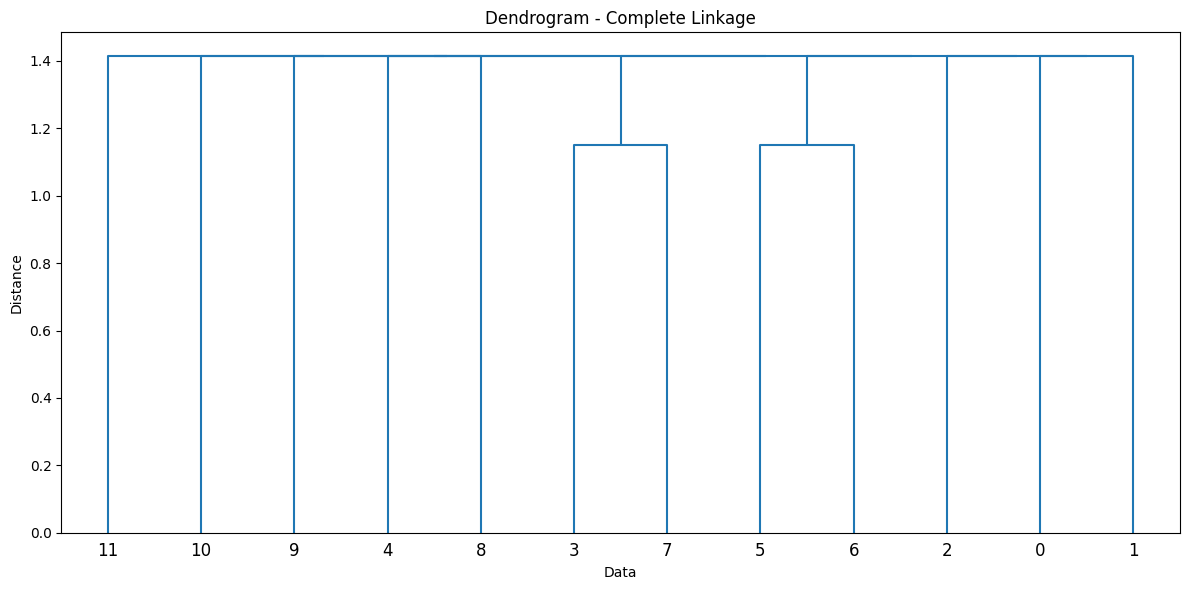

In [ ]:
linkage_complete = linkage(
    df_FE,
    method="complete",
    metric="euclidean"
)

plt.figure(figsize=(12, 6))
dendrogram(linkage_complete)
plt.title("Dendrogram - Complete Linkage")
plt.xlabel("Data")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()



```
Membentuk 5 cluster menggunakan Complete Linkage
```



In [ ]:
hierarchical_complete = AgglomerativeClustering(
    n_clusters=n_clusters,
    linkage="complete",
    metric="euclidean"
)

labels_complete = hierarchical_complete.fit_predict(df_FE)
df_preprocessed["Complete_label"] = labels_complete

print("Hasil cluster Complete Linkage:")
display(df_preprocessed[["prepro", "Complete_label"]])

score_complete = silhouette_score(
    df_FE,
    labels_complete,
    metric="euclidean"
)
print("Silhouette Score Complete Linkage:", score_complete)

print("Jumlah anggota setiap cluster Complete Linkage:")
display(df_preprocessed["Complete_label"].value_counts().sort_index())


Hasil cluster Complete Linkage:


,prepro,Complete_label
0,biss jaggery modak,0
1,honey cookies,0
2,gingerbread waffles,0
3,sauerkraut fish salad,0
4,carrot bean fritters,1
5,apple pie,0
6,quark rhubarb pie,0
7,papaya salad,0
8,chicken,1
9,salmon,3


Silhouette Score Complete Linkage: 0.01035973449936323
Jumlah anggota setiap cluster Complete Linkage:


,count
Complete_label,
0,7
1,2
2,1
3,1
4,1




```
Membuat dendrogram Average Linkage
```



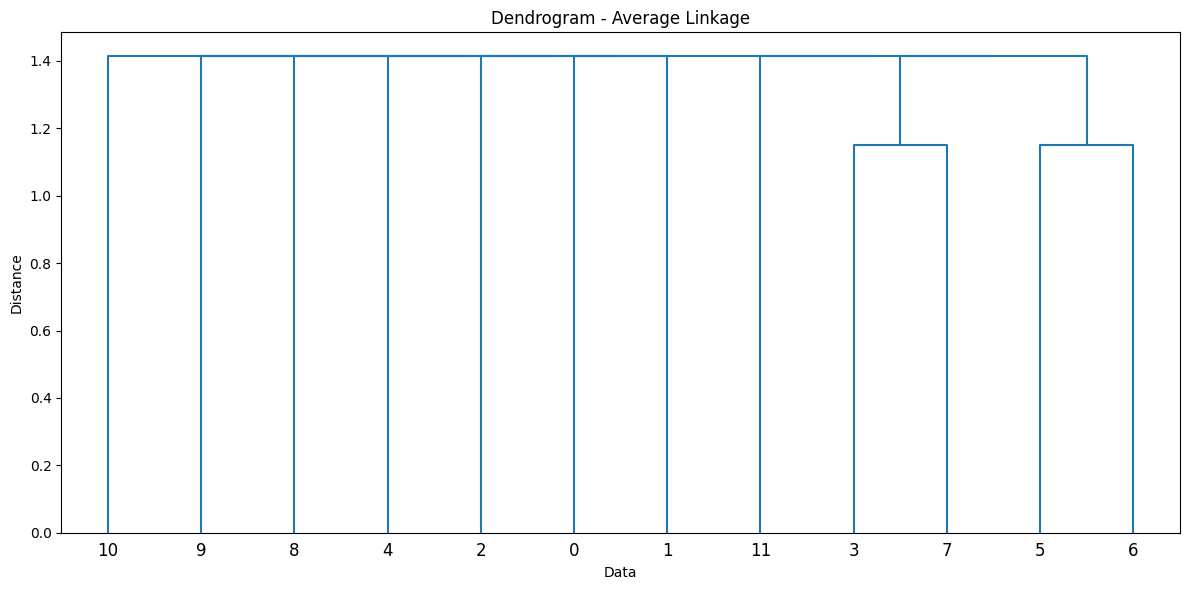

In [ ]:
linkage_average = linkage(
    df_FE,
    method="average",
    metric="euclidean"
)

plt.figure(figsize=(12, 6))
dendrogram(linkage_average)
plt.title("Dendrogram - Average Linkage")
plt.xlabel("Data")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()



```
Membentuk 5 cluster menggunakan Average Linkage
```



In [ ]:
hierarchical_average = AgglomerativeClustering(
    n_clusters=n_clusters,
    linkage="average",
    metric="euclidean"
)

labels_average = hierarchical_average.fit_predict(df_FE)
df_preprocessed["Average_label"] = labels_average

print("Hasil cluster Average Linkage:")
display(df_preprocessed[["prepro", "Average_label"]])

score_average = silhouette_score(
    df_FE,
    labels_average,
    metric="euclidean"
)
print("Silhouette Score Average Linkage:", score_average)

print("Jumlah anggota setiap cluster Average Linkage:")
display(df_preprocessed["Average_label"].value_counts().sort_index())

Hasil cluster Average Linkage:


,prepro,Average_label
0,biss jaggery modak,0
1,honey cookies,0
2,gingerbread waffles,0
3,sauerkraut fish salad,3
4,carrot bean fritters,0
5,apple pie,1
6,quark rhubarb pie,1
7,papaya salad,3
8,chicken,0
9,salmon,0


Silhouette Score Average Linkage: 0.06215840699617925
Jumlah anggota setiap cluster Average Linkage:


,count
Average_label,
0,6
1,2
2,1
3,2
4,1




```
Membuat dendrogram Ward Linkage
```



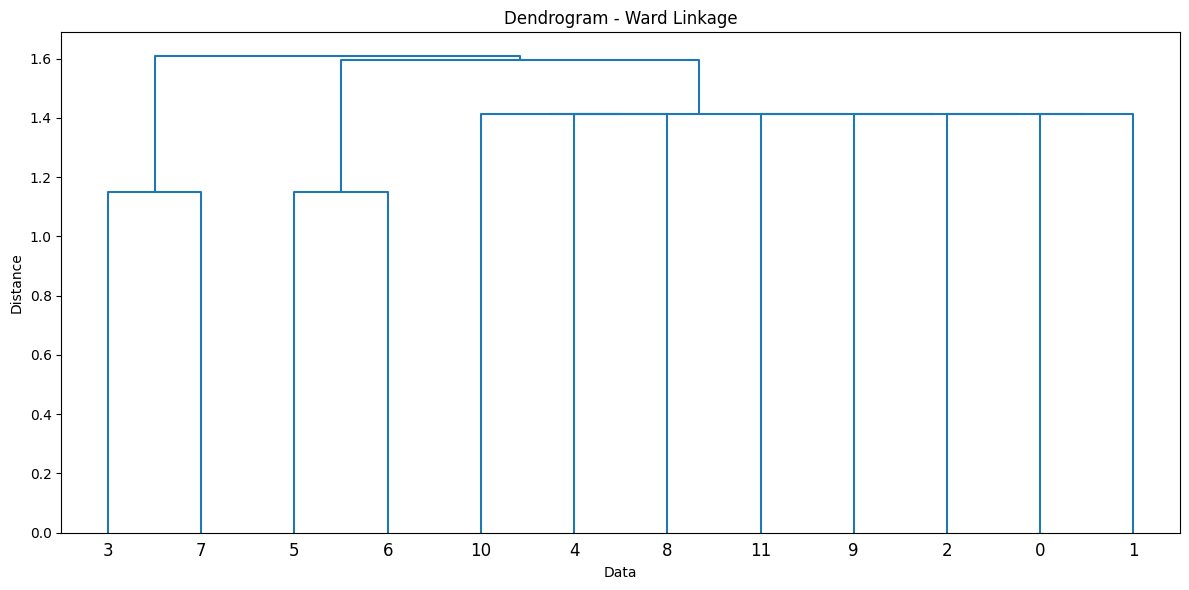

In [ ]:
linkage_ward = linkage(
    df_FE,
    method="ward",
    metric="euclidean"
)

plt.figure(figsize=(12, 6))
dendrogram(linkage_ward)
plt.title("Dendrogram - Ward Linkage")
plt.xlabel("Data")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()



```
Membentuk 5 cluster menggunakan Ward Linkage
```



In [ ]:
hierarchical_ward = AgglomerativeClustering(
    n_clusters=n_clusters,
    linkage="ward",
    metric="euclidean"
)

labels_ward = hierarchical_ward.fit_predict(df_FE)
df_preprocessed["Ward_label"] = labels_ward

print("Hasil cluster Ward Linkage:")
display(df_preprocessed[["prepro", "Ward_label"]])

score_ward = silhouette_score(
    df_FE,
    labels_ward,
    metric="euclidean"
)
print("Silhouette Score Ward Linkage:", score_ward)

print("Jumlah anggota setiap cluster Ward Linkage:")
display(df_preprocessed["Ward_label"].value_counts().sort_index())

Hasil cluster Ward Linkage:


,prepro,Ward_label
0,biss jaggery modak,1
1,honey cookies,1
2,gingerbread waffles,1
3,sauerkraut fish salad,3
4,carrot bean fritters,0
5,apple pie,2
6,quark rhubarb pie,2
7,papaya salad,3
8,chicken,0
9,salmon,1


Silhouette Score Ward Linkage: 0.062158406996179194
Jumlah anggota setiap cluster Ward Linkage:


,count
Ward_label,
0,3
1,4
2,2
3,2
4,1




```
Membandingkan nilai Silhouette Score dari metode Complete Linkage, Average Linkage, dan Ward Linkage
```



In [ ]:
hasil_perbandingan = pd.DataFrame({
    "Metode Clustering": [
        "Complete Linkage",
        "Average Linkage",
        "Ward Linkage"
    ],
    "Silhouette Score": [
        score_complete,
        score_average,
        score_ward
    ]
})

hasil_perbandingan = hasil_perbandingan.sort_values(
    by="Silhouette Score",
    ascending=False
).reset_index(drop=True)

display(hasil_perbandingan)

,Metode Clustering,Silhouette Score
0,Average Linkage,0.062158
1,Ward Linkage,0.062158
2,Complete Linkage,0.010360


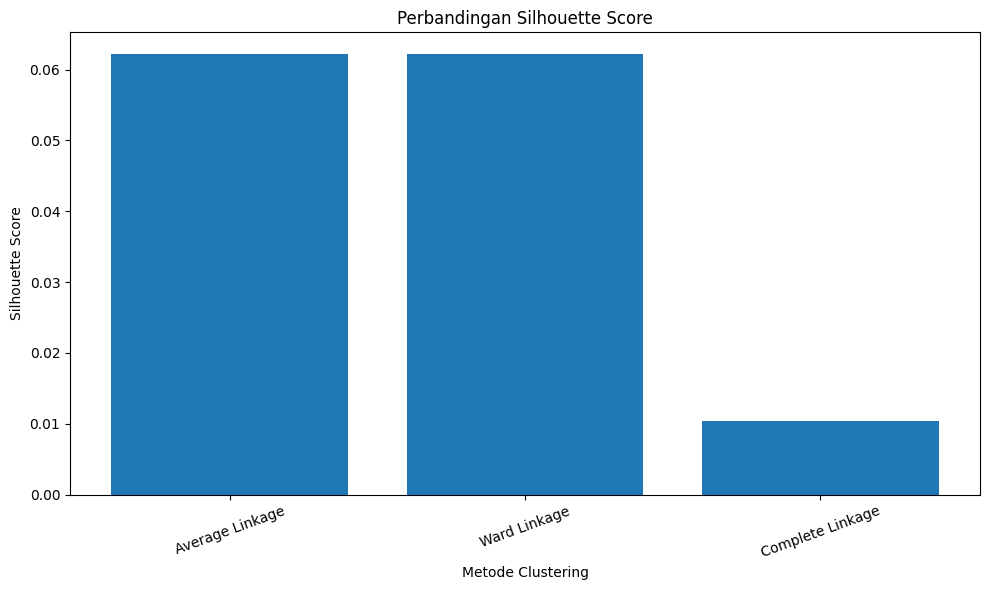

Metode dengan Silhouette Score tertinggi adalah Average Linkage dengan nilai 0.0622


In [ ]:
plt.figure(figsize=(10, 6))
plt.bar(
    hasil_perbandingan["Metode Clustering"],
    hasil_perbandingan["Silhouette Score"]
)
plt.xlabel("Metode Clustering")
plt.ylabel("Silhouette Score")
plt.title("Perbandingan Silhouette Score")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

metode_terbaik = hasil_perbandingan.iloc[0]
print(
    "Metode dengan Silhouette Score tertinggi adalah",
    metode_terbaik["Metode Clustering"],
    "dengan nilai",
    round(metode_terbaik["Silhouette Score"], 4)
)



```
Perbandingan Label Cluster
```



In [ ]:
hasil_cluster = df_preprocessed[
    [
        "prepro",
        "Complete_label",
        "Average_label",
        "Ward_label"
    ]
]

display(hasil_cluster)

,prepro,Complete_label,Average_label,Ward_label
0,biss jaggery modak,0,0,1
1,honey cookies,0,0,1
2,gingerbread waffles,0,0,1
3,sauerkraut fish salad,0,3,3
4,carrot bean fritters,1,0,0
5,apple pie,0,1,2
6,quark rhubarb pie,0,1,2
7,papaya salad,0,3,3
8,chicken,1,0,0
9,salmon,3,0,1



> Analisis Hasil Ketiga Metode



Analisis dilakukan dengan memperhatikan dendrogram, pembagian jumlah dokumen pada setiap cluster, dan nilai Silhouette Score. Label angka cluster pada setiap metode tidak harus sama karena penomoran cluster bersifat arbitrer.

Gunakan hasil tabel dan grafik setelah seluruh sel dijalankan untuk menyusun kesimpulan. Metode dengan Silhouette Score tertinggi dapat dianggap memiliki kualitas pemisahan cluster terbaik di antara metode yang diuji pada dataset ini. Perhatikan juga distribusi anggota cluster agar penilaian tidak hanya bergantung pada satu nilai.